# ML Model with actual goals

In [15]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
#from functools import cache
import warnings

NUM_OF_COUNTRIES = 5
NUM_OF_SEASONS = 25
NUM_OF_MATCHES = 9130
NUM_OF_MATCHES_IN_A_SEASON = 1826
SEED = 1893

np.random.seed(SEED)
warnings.filterwarnings('ignore')


In [16]:
def score_from_amount_and_diff(amount, diff):
    if diff < 0:
        home_score = (amount + diff) / 2
        away_score = home_score - diff
    else:
        away_score = (amount - diff) / 2
        home_score = away_score + diff

    # cut excess floating numbers
    if (home_score - int(home_score)) == 0 and (away_score - int(away_score)) == 0:
        home_score = int(home_score)
        away_score = int(away_score)

    return home_score, away_score


def print_formatted_pred_score(country, season, matchnumber, ht_name, at_name, ht_pred_score, at_pred_score, ht_actual_score, at_actual_score):
    print("%4s %3s %3s %20s %20s %15s | %6s" %
          (country, season, matchnumber, ht_name, at_name,
           str(ht_pred_score)[0:4] + ":" + str(at_pred_score)[0:4],
           f"{ht_actual_score}:{at_actual_score}"))


def closed_form_solution(X, y):
    # alternative: np.dot(np.linalg.inv(np.dot(X.T, X)), np.dot(X.T, y))
    return np.linalg.solve(np.dot(X.T, X), np.dot(X.T, y))


def h(X, w):
    return np.matmul(X, w)[0]


In [17]:
df_matches = pd.read_csv('matches_ac.csv', sep=';')
df_matches['bias'] = 1

noise = np.random.normal(0, 0.01, df_matches.shape[0] * 10)

for index, row in df_matches.iterrows():
    # ht
    if row["ht_curr_eff_chancediff"] == 0:
        df_matches.at[index, "ht_curr_eff_chancediff"] = noise[index]
    if row["ht_past_chancediff_combined"] == 0:
        df_matches.at[index,
                      "ht_past_chancediff_combined"] = noise[df_matches.shape[0] + index]
    if row["ht_curr_eff_chanceamount"] == 0:
        df_matches.at[index,
                      "ht_curr_eff_chanceamount"] = noise[df_matches.shape[0] * 2 + index]
    if row["ht_past_chanceamount"] == 0:
        df_matches.at[index,
                      "ht_past_chanceamount"] = noise[df_matches.shape[0] * 3 + index]
    # at
    if row["at_curr_eff_chancediff"] == 0:
        df_matches.at[index,
                      "at_curr_eff_chancediff"] = noise[df_matches.shape[0] * 4 + index]
    if row["at_past_chancediff_combined"] == 0:
        df_matches.at[index,
                      "at_past_chancediff_combined"] = noise[df_matches.shape[0] * 5 + index]
    if row["at_curr_eff_chanceamount"] == 0:
        df_matches.at[index,
                      "at_curr_eff_chanceamount"] = noise[df_matches.shape[0] * 6 + index]
    if row["at_past_chanceamount"] == 0:
        df_matches.at[index,
                      "at_past_chanceamount"] = noise[df_matches.shape[0] * 7 + index]
    # label
    if row["actual_goaldiff"] == 0:
        df_matches.at[index,
                      "actual_goaldiff"] = noise[df_matches.shape[0] * 8 + index]
    if row["actual_goalamount"] == 0:
        df_matches.at[index,
                      "actual_goalamount"] = noise[df_matches.shape[0] * 9 + index]

ga_feature_set = ["ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
                  "ht_past_chanceamount", "at_past_chanceamount", "bias"]
gd_feature_set = ["ht_curr_eff_chancediff", "at_curr_eff_chancediff", "ht_past_chancediff_combined", "at_past_chancediff_combined",
                  "ht_market_value_ln_relative", "at_market_value_ln_relative", "bias"]
ga_label = ["actual_goalamount"]
gd_label = ["actual_goaldiff"]

df_matches


,country,season,matchnumber,ht_name,at_name,ht_curr_eff_chancediff,at_curr_eff_chancediff,ht_past_chancediff_combined,at_past_chancediff_combined,ht_curr_eff_chanceamount,at_curr_eff_chanceamount,ht_past_chanceamount,at_past_chanceamount,ht_market_value_ln_relative,at_market_value_ln_relative,ht_is_promoter,at_is_promoter,actual_goalamount,actual_goaldiff,bias
0,ENG,14,1,Queens Park Rangers,Hull,-0.000107,-0.006322,0.005476,0.002399,-0.006037,0.012542,0.006067,-0.005316,-0.392415,-0.348740,True,False,1,-1,1
1,ENG,14,1,Newcastle,Man City,-0.002312,0.004580,0.002748,0.007405,0.008663,0.001433,-0.000951,-0.003893,-0.169272,1.002768,False,False,2,-2,1
2,ENG,14,1,Burnley,Chelsea,-0.004361,-0.000947,-0.009217,-0.020822,-0.010237,0.010523,-0.005959,0.010205,-1.140622,1.211651,True,False,4,-2,1
3,ENG,14,1,Arsenal,Crystal Palace,0.007917,0.024501,0.008286,0.010394,0.001439,0.007554,-0.013947,0.000835,0.917365,-0.536203,False,False,3,1,1
4,ENG,14,1,West Ham,Tottenham,0.004695,-0.004871,0.002485,-0.000451,0.001249,0.018424,0.008236,0.009088,-0.198259,0.606114,False,False,1,-1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9125,ITA,18,38,Frosinone,Chievo,-4.492426,-4.452152,-3.581579,-1.943421,-2.059192,-2.232642,4.228070,4.508772,-1.394930,-1.394930,True,False,0,0,1
9126,ITA,18,38,Fiorentina,CFC Genoa,1.172165,-1.286395,1.539474,-1.361842,0.407509,-0.820735,6.789474,4.719298,0.350310,-0.144768,False,False,0,0,1
9127,ITA,18,38,Bologna,Napoli,-0.932129,5.242267,-1.497368,5.293421,-0.446689,3.415385,4.350877,8.877193,-0.614771,1.070083,False,False,5,1,1
9128,ITA,18,38,Inter,Empoli,2.881676,-3.462648,2.380263,-3.058772,1.042860,-0.805584,6.754386,4.403509,1.024225,-0.738824,False,True,3,1,1


## general weights

In [18]:

training_data = df_matches.query(f"season <= 17")

X_training_data_ga = training_data[ga_feature_set].values

X_training_data_gd = training_data[gd_feature_set].values

y_training_data_ga = training_data[ga_label].values
y_training_data_gd = training_data[gd_label].values

w_ga = closed_form_solution(X_training_data_ga, y_training_data_ga)
w_gd = closed_form_solution(X_training_data_gd, y_training_data_gd)

print("weights goalamount:\n", w_ga)
print("weights goaldiff:\n", w_gd)


weights goalamount:
 [[ 0.10006147]
 [ 0.07660235]
 [ 0.05769823]
 [-0.0265773 ]
 [ 2.56962056]]
weights goaldiff:
 [[ 0.08575878]
 [-0.06174588]
 [-0.03341073]
 [-0.03966185]
 [ 0.61651866]
 [-0.52173928]
 [ 0.38458502]]


## weights per matchnumber

In [19]:
ga_weights, gd_weights = [], []
for i in range(1,39):
    training_data = df_matches.query(f"season <= 17 and matchnumber == {i}")

    X_training_data_ga = training_data[ga_feature_set].values
    X_training_data_gd = training_data[gd_feature_set].values
    y_training_data_ga = training_data[ga_label].values
    y_training_data_gd = training_data[gd_label].values

    ga_weights.append(closed_form_solution(
        X_training_data_ga, y_training_data_ga))
    gd_weights.append(closed_form_solution(
        X_training_data_gd, y_training_data_gd))

print("weights goalamount match no 1:\n", ga_weights[0])
print("weights goaldiff match no 1:\n", gd_weights[0])
print("weights goalamount match no 18:\n", ga_weights[17])
print("weights goaldiff match no 18:\n", gd_weights[17])


weights goalamount match no 1:
 [[22.19810883]
 [16.17143456]
 [ 0.18875775]
 [-0.09829112]
 [ 2.1158403 ]]
weights goaldiff match no 1:
 [[24.77769424]
 [-0.0512528 ]
 [ 0.23979615]
 [-0.10856374]
 [ 0.4953144 ]
 [-0.25577838]
 [ 0.17773291]]
weights goalamount match no 18:
 [[ 0.16423086]
 [ 0.06128271]
 [-0.04308817]
 [ 0.06179257]
 [ 2.66540828]]
weights goaldiff match no 18:
 [[ 1.92363121e-01]
 [-1.38416606e-01]
 [ 4.77240029e-02]
 [ 3.20790800e-04]
 [ 2.66449614e-01]
 [-8.81646335e-02]
 [ 3.45171694e-01]]


## error general weights

In [20]:
training_data_df, test_data_df = df_matches.query(f"season < 18"), df_matches.query(f"season == 18")

ga_squared_error, gd_squared_error = 0, 0

for index, row in test_data_df.iterrows():
    X_input_ga = row[ga_feature_set].values
    X_input_gd = row[gd_feature_set].values

    ga_pred, gd_pred = h(X_input_ga, w_ga), h(X_input_gd, w_gd)
    ht_score_pred, at_score_pred = score_from_amount_and_diff(ga_pred, gd_pred)
    actual_ht_score, actual_at_score = score_from_amount_and_diff(
        row["actual_goalamount"], row["actual_goaldiff"])
    ga_squared_error += np.square(ga_pred - row["actual_goalamount"])
    gd_squared_error += np.square(gd_pred - row["actual_goaldiff"])

    print_formatted_pred_score(
        row["country"], row["season"], row["matchnumber"], row["ht_name"], row["at_name"], ht_score_pred, at_score_pred, actual_ht_score, actual_at_score)
    
print("Squared error goalamount", ga_squared_error / NUM_OF_MATCHES_IN_A_SEASON)
print("Squared error goaldiff", gd_squared_error / NUM_OF_MATCHES_IN_A_SEASON)


 ENG  18   1               Wolves              Everton       1.41:1.23 |    2:2
 ENG  18   1              Watford             Brighton       1.66:1.06 |    2:0
 ENG  18   1          Southampton              Burnley       1.71:1.05 |    0:0
 ENG  18   1            Newcastle            Tottenham       1.08:1.53 |    1:2
 ENG  18   1              Man Utd            Leicester       1.74:1.02 |    2:1
 ENG  18   1              Arsenal             Man City       1.31:1.47 |    0:2
 ENG  18   1         Huddersfield              Chelsea       0.87:1.73 |    0:3
 ENG  18   1               Fulham       Crystal Palace       1.54:1.12 |    0:2
 ENG  18   1          Bournemouth              Cardiff       1.90:0.86 |    2:0
 ENG  18   1            Liverpool             West Ham       1.95:0.92 |    4:0
 ENG  18   2            Tottenham               Fulham       2.55:0.58 |    3:1
 ENG  18   2              Everton          Southampton       1.82:0.84 |    2:1
 ENG  18   2             West Ham       

## error weights per matchnumber

In [21]:
ga_squared_error, gd_squared_error = 0, 0

for index, row in test_data_df.iterrows():
    X_input_ga = row[ga_feature_set].values
    X_input_gd = row[gd_feature_set].values
    ga_squared_error += np.square(h(X_input_ga,
                                    ga_weights[int(row["matchnumber"])-1]) - row["actual_goalamount"])
    gd_squared_error += np.square(h(X_input_gd,
                                    gd_weights[int(row["matchnumber"])-1]) - row["actual_goaldiff"])

print("Squared error goalamount", ga_squared_error / NUM_OF_MATCHES_IN_A_SEASON)
print("Squared error goaldiff", gd_squared_error / NUM_OF_MATCHES_IN_A_SEASON)


Squared error goalamount 2.8184784866723427
Squared error goaldiff 2.6728346439452015


## Training error general weights

In [28]:
training_error_data = dict()
ga_squared_training_error, gd_squared_training_error = 0,0
prev_matchnumber = 0

for index, row in training_data_df.iterrows():
      if row["season"] == 14 and row["matchnumber"] == 1:
            ga_pred, gd_pred = 0,0
      else:
            if int(row["matchnumber"]) > prev_matchnumber:
                  curr_training_data_df = training_data_df.query(f"season < {row['season']} or (season == {row['season']} and matchnumber < {row['matchnumber']})")
                  X_data_train_ga, X_data_train_gd = curr_training_data_df[ga_feature_set], curr_training_data_df[gd_feature_set]
                  y_data_train_ga, y_data_train_gd = curr_training_data_df[ga_label], curr_training_data_df[gd_label]
                  curr_ga_weight = closed_form_solution(X_data_train_ga, y_data_train_ga)
                  curr_gd_weight = closed_form_solution(X_data_train_gd, y_data_train_ga)

            X_input_ga = row[ga_feature_set].values
            X_input_gd = row[gd_feature_set].values

            ga_pred, gd_pred = h(X_input_ga, curr_ga_weight), h(
            X_input_gd, curr_gd_weight)

      ht_score_pred, at_score_pred = score_from_amount_and_diff(ga_pred, gd_pred)
      actual_ht_score, actual_at_score = score_from_amount_and_diff(
            row["actual_goalamount"], row["actual_goaldiff"])
      ga_squared_training_error += np.square(ga_pred - row["actual_goalamount"])
      gd_squared_training_error += np.square(gd_pred - row["actual_goaldiff"])

      if row["country"] not in training_error_data.keys():
            training_error_data[row["country"]] = {}
      if row["season"] not in training_error_data[row["country"]].keys():
            training_error_data[row["country"]][row["season"]] = {}
      if row["matchnumber"] not in training_error_data[row["country"]][row["season"]].keys():
            training_error_data[row["country"]
                                ][row["season"]][row["matchnumber"]] = {"squared_error_ga":0,"squared_error_gd":0}
      if row["country"] == "GER":
            training_error_data[row["country"]
                                ][row["season"]][row["matchnumber"]]["squared_error_ga"] += np.square(ga_pred - row["actual_goalamount"]) / 9
            training_error_data[row["country"]
                                ][row["season"]][row["matchnumber"]]["squared_error_gd"] += np.square(gd_pred - row["actual_goaldiff"]) / 9
      else:
            training_error_data[row["country"]
                                ][row["season"]][row["matchnumber"]]["squared_error_ga"] += np.square(ga_pred - row["actual_goalamount"]) / 10
            training_error_data[row["country"]
                                ][row["season"]][row["matchnumber"]]["squared_error_gd"] += np.square(gd_pred - row["actual_goaldiff"]) / 10

print("Squared error goalamount",
      ga_squared_training_error / (NUM_OF_MATCHES_IN_A_SEASON*4))
print("Squared error goaldiff", gd_squared_training_error /
      (NUM_OF_MATCHES_IN_A_SEASON*4))


Squared error goalamount 23.17281918777686
Squared error goaldiff 185.4729095990362


In [42]:

print("country;season_matchnumber;squared_error_ga;squared_error_gd")
for a in training_error_data.keys():
      for b in training_error_data[a].keys():
            for c in training_error_data[a][b].keys():
                  print(a+";"+str(b)+"_"+str(c)+";" +
                        str(training_error_data[a][b][c]["squared_error_ga"])+";"+str(training_error_data[a][b][c]["squared_error_gd"]))


country;season_matchnumber;squared_error_ga;squared_error_gd
ENG;14_1;8.200000000000001;1.4000000000000004
ENG;14_2;198.55820456494465;18974.326553952564
ENG;14_3;7.890043775588315;13.766925239541592
ENG;14_4;4.1873131786261;7.266248782232686
ENG;14_5;5.446806664061956;9.996399452057926
ENG;14_6;2.519710389174177;6.413155385339757
ENG;14_7;1.1057774426702853;3.920026231119276
ENG;14_8;5.005825099418355;9.37646896684584
ENG;14_9;1.5772199968189198;8.553896885279547
ENG;14_10;2.1921620363789;8.209356062040333
ENG;14_11;1.3878870679648025;7.317931157390766
ENG;14_12;1.2800796766367206;6.07520876706738
ENG;14_13;2.174729142345946;7.409531219232843
ENG;14_14;1.4996504458851183;9.3633907242846
ENG;14_15;3.207927964230941;4.749210920646813
ENG;14_16;1.4593457406303725;4.087666247253631
ENG;14_17;1.3086246450692447;6.185771358510757
ENG;14_18;1.659934173230473;10.404574081496397
ENG;14_19;3.6140609974087505;6.349029688613394
ENG;14_20;5.6000752273894925;4.4847474315946405
ENG;14_21;1.150759735

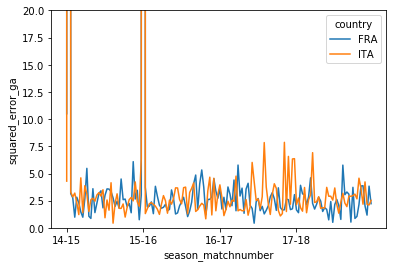

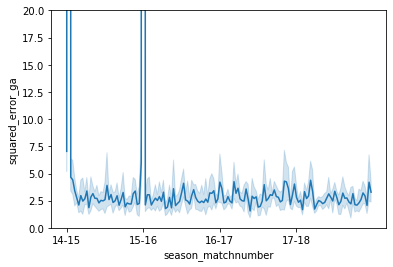

In [65]:
training_error_df = pd.read_csv('training_error.csv', sep=';')
sns.lineplot(data=training_error_df.query("country == 'ITA' or country == 'FRA'"),
             x="season_matchnumber", y="squared_error_ga", hue="country")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], ["14-15","15-16","16-17","17-18"])
plt.ylim(0,20)
# sumed_df = pd.DataFrame()
# sumed_df["season_matchnumber"] = seasons
# total = []
# for season in seasons:
#     total.append(np.sum(training_error_df.groupby(["matchnumber"]).get_group(
#         season)["squared_error_ga"]) / NUM_OF_COUNTRIES)
# sumed_df["squared_error_ga"] = total
plt.show()
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="squared_error_ga")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 20)
plt.show()


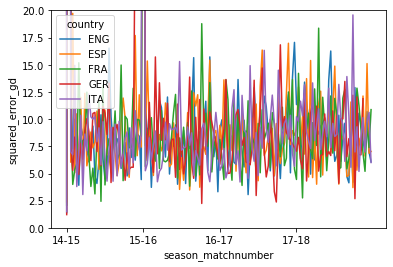

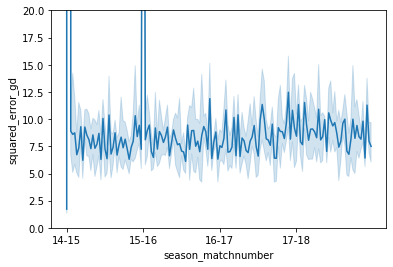

In [58]:
training_error_df = pd.read_csv('training_error.csv', sep=';')
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="squared_error_gd", hue="country")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 30)
# sumed_df = pd.DataFrame()
# sumed_df["season_matchnumber"] = seasons
# total = []
# for season in seasons:
#     total.append(np.sum(training_error_df.groupby(["matchnumber"]).get_group(
#         season)["squared_error_ga"]) / NUM_OF_COUNTRIES)
# sumed_df["squared_error_ga"] = total
plt.show()
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="squared_error_gd")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 30)
plt.show()
